## Gradual contingency degradation and habit expression

## Classes

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy.special as scp
from itertools import product
import matplotlib.ticker as ticker
from matplotlib.ticker import MultipleLocator
from scipy.optimize import curve_fit
# from classes import Agent, MultiArmedBandit, World
# from utilities import run_all_simulations, create_long_df_gradual, run_simulation

np.set_printoptions(suppress=True)
sns.set_style("whitegrid")


def run_simulation(h=1000,
                   training_protocol = [0,0,1,1],
				   TAU=4,
				   rep=1,
				   na=2,
				#    nb=2,
				#    ns=3,
				#    no=3,
				   nr=3,
				   nc=2,
				   T=2,
				   approx_pred_pol = True,
				   approx_pred_rew = True,
				   utility = np.array([0.98,0.01, 0.01]),
				   Rho = None,
				   reward_decay_rate = None,
				   debug=False,
				   context_volatility=0.98):
	
	
	'''           define policies            '''
	npi = na**(T-1)
	# policies = list(product(list(np.arange(na))*(T-1)))
	policies = np.array(list(product( np.arange(na), repeat= T-1)))


	'''       define p(s_t|s_t-1, a_t-1)      '''
	prior_states = np.array([0]*nb + [1]) # np.array([0,0,1])
	state_transition_matrix = np.array([np.eye(nb+1)]*nb).transpose([1,2,0])
	state_transition_matrix[:,-1,:] = np.eye(nb+1)[:,:-1]
	# print(f"==>> state_transition_matrix:\n {state_transition_matrix[:,:,0]}")
	# print(f"==>> state_transition_matrix:\n {state_transition_matrix[:,:,1]}")

	state_transition_matrix = np.zeros([ns,ns,na])
	for b in range(nb):
		state_transition_matrix[b,:,b] = 1

	# print(f"==>> state_transition_matrix:\n {state_transition_matrix[:,:,0]}")
	# print(f"==>> state_transition_matrix:\n {state_transition_matrix[:,:,1]}")


	'''          define p(o_t|s_t)            '''
	
	observation_generation_matrix = np.eye(ns)
	
	'''           define p(r|s,c)             '''
	lambda_H = np.ones([nr,ns])
	lambda_H[-1,-1] = 100
	counts_prior_rewards = np.stack([lambda_H for i in range(nc)],axis=-1)
	# counts_prior_rewards += np.random.uniform(low=0,high=0.5, size = counts_prior_rewards.shape)
	
	bias = 1
	init_counts = np.ones([nr,nb+1])
	init_counts[0,0] = bias
	init_counts[1,1:] = bias
	init_counts[:,-1] = [1,1,100]
	counts_prior_rewards[:,:,0] = init_counts


	prior_rewards = counts_prior_rewards / counts_prior_rewards.sum(axis=0)

	'''              define p(pi|c)           '''
	counts_prior_policies = np.zeros([npi,nc]) + h


	prior_policies = counts_prior_policies / counts_prior_policies.sum(axis=0)


	'''       define prior over contexts p(c) '''
	prior_context = np.array([0.9] + [1-0.9]*(nc-1))

	p = 0.9
	q = 1-p

	'''   p(c_t|c_t-1)'''

	q = (1-context_volatility)/(nc-1)
	context_transition_matrix = np.eye(nc)*(1-nc*q) + q
	assert(np.all(context_transition_matrix.sum(axis=0) == 1))

	'''   define Env reward generation matrix if not passed as argument'''
	if Rho is None:
		p = 0.9
		q = 1-p
		bandits = np.arange(nb)
		Rho = np.ones([nr,ns,len(bandits)])*q

		for context,b in enumerate(bandits):
			Rho[0,b,context] = p
			Rho[1,np.arange(nb+1) != b,context] = p

		Rho[-1,:] = 0
		Rho[:,-1] = 0
		Rho[-1,-1] = 1

		Rho = Rho[:,:,training_protocol]
		
	# Plot task setup

	'''Plot state transition matrix'''
	if False:
	
		fig,axes = plt.subplots(1,2,figsize=(10,4))

		for ai, ax,title in zip([0,1], axes, ['$a_1$ = L1', '$a_2$ = L2']):
			ax.xaxis.tick_top()
			sns.heatmap(state_transition_matrix[:,:,ai],annot=True,ax=ax, cbar=False)
			ax.set_xticklabels(['L1','L2','M'],minor=False);
			ax.set_yticklabels(['L1','L2','M'])
			ax.set_title(title);

		'''Plot likelihood matrix'''
	
		fig, ax = plt.subplots()
		ax = sns.heatmap(prior_rewards[...,0],cbar=False,annot=True)
		ax.set_xticklabels(['L1','L2','M'],minor=False)
		ax.set_yticklabels(['$r_1$', '$r_2$', '$r_3$'])
		ax.set_title('Reward generation beliefs')


		'''Plot Environment reward generation matrix'''

		fig,axes = plt.subplots(1,2,figsize=(10,4))
		sns.heatmap(Rho[:,:,0],annot=True,ax=axes[0], cbar=False)
		sns.heatmap(Rho[:,:,-1],annot=True,ax=axes[1], cbar=False)
		for ai, ax,title in zip([0,1], axes, ['Reward Regime 1', 'Reward Regime 2']):
			ax.xaxis.tick_top()
			ax.set_xticklabels(['L1','L2','M'],minor=False)
			ax.set_yticklabels(['$r_1$', '$r_2$', '$r_3$'])
			ax.set_title(title)


	# Run Simulations
	env = MultiArmedBandit(state_transition_matrix,
						Rho, 
						TAU=TAU,
						T=T,
						n_bandits = nb,
						training_protocol=training_protocol,
						observation_generation_matrix=observation_generation_matrix,
						no=no)

	agent = Agent(
			state_transition_matrix,
			utility,
			policies,
			prior_rewards,
			counts_prior_rewards,
			prior_policies,
			counts_prior_policies,
			prior_states,
			prior_context,
			na,
			nc,
			env,
			approx_pred_pol = approx_pred_pol,
			approx_pred_rew = approx_pred_rew,
			observation_generation_matrix = observation_generation_matrix,
			debug=debug,
			context_transition_matrix = context_transition_matrix
			)

	world = World(agent, env)

	world.simulate_experiment()

	return world 


def fit_posterior_traces(q_context, q_action, switch, TAU):
    """Fit sigmoid/exponential functions to context and policy posterior traces."""

    sigmoid = lambda t, a, b, c, d: d + a / (1 + np.exp(-b * (t - c)))
    exponential = lambda t, b, c, d: d + np.exp(b * (t - c))

    t = np.arange(1, TAU + 1)

    try:
        context_params, context_pcov = curve_fit(sigmoid, t, q_context, p0=[1., 1., switch, 0.])
        context_func = 0
    except RuntimeError:
        try:
            exponential_params, exponential_pcov = curve_fit(exponential, t, q_context, p0=[1., switch, 0.])
            context_params = np.zeros(4)
            context_params[0] = 1.
            context_params[1:] = exponential_params
            context_pcov = np.eye(4)
            context_pcov[1:, 1:] = exponential_pcov
            context_func = 1
        except RuntimeError:
            context_params = np.full(4, np.nan)
            context_pcov = np.full((4, 4), np.nan)
            context_func = np.nan

    try:
        policy_params, policy_pcov = curve_fit(sigmoid, t[10:], q_action[10:], p0=[1., 1., switch, 0.])
        policy_func = 0
    except RuntimeError:
        try:
            exponential_params, policy_pcov = curve_fit(exponential, t[10:], q_action[10:], p0=[1., switch, 0.])
            policy_params = np.zeros(4)
            policy_params[0] = 1.
            policy_params[1:] = exponential_params
            policy_func = 1
        except RuntimeError:
            policy_params = np.full(4, np.nan)
            policy_pcov = np.full((3, 3), np.nan)
            policy_func = np.nan

    se = np.sqrt(np.diag(context_pcov)) if np.all(np.isfinite(context_pcov)) else np.full(4, np.nan)

    return context_params, context_pcov, context_func, policy_params, policy_func, se


def run_degradation_simulations(hs=np.array([1,10,1000]), context_volatility=0.99, utility=np.array([0.025,0.9,0.025]),k_range=np.array([0.007, 0.02, 3]), switch=10,\
								na=2, nr=3, nc=2, nsims=5, train_trials=0, TAU=20, T=2, debug=False, sim_name=None):


	nb = na
	ns = nb + 1
	no = ns
	npi = na**(T-1)


	"""agent params"""
	# hs = np.array(hs)
	utilities = np.array([utility])
	agent_instance = np.arange(nsims)
	context_volatilities = np.array([context_volatility])

	"""environment params"""

	# create training protocol
	training_protocol = [np.array([0]*(switch+train_trials) + [1]*switch)]
	
	
	# create training regimes
	start = 0.9
	stop = 0.1
	logistic = lambda x, k: stop - (0.8) / (np.exp(switch*k) - 1) + (np.exp(switch*k) + 1) / (np.exp(switch*k) - 1)*(start-stop)/(1+np.exp(k*(x-switch)))
	
	Rhos = []
	for k in k_range:
		x = np.arange(0,switch*2,1)
		p_win = logistic(x,k)
		a = np.array([[1-p_win, p_win, np.array([0]*switch*2)],\
					[p_win, 1-p_win, np.array([0]*switch*2)],\
					[np.array([0]*switch*2), np.array([0]*switch*2), np.array([1]*switch*2)]])
		
		Rho = np.zeros([nr,ns,TAU])
		Rho[:,:,train_trials:] = a
		Rho[:,:,:train_trials] = Rho[:,:,train_trials][:,:,None] 
		
		Rhos.append([Rho,k])

	## construct list of simulations
	parameter_combinations = product(agent_instance, hs, utilities, training_protocol, context_volatilities, Rhos)
	sim_params = []



	for p in parameter_combinations:
		# sim specific params
		pars = {}
		pars["rep"] = p[0]
		pars["h"] = p[1]
		pars["utility"] = p[2]
		pars["training_protocol"] = p[3]
		pars["context_volatility"] = p[4]
		pars["Rho"] = p[5][0]

		## global params
		pars["TAU"] = TAU
		pars["na"] = na
		pars["nb"] =  nb
		pars["ns"] = ns
		pars["no"] = no
		pars["nr"] =  nr
		pars["nc"] = nc
		pars["T"] = T
		pars["debug"] = debug
		pars["reward_decay_rate"] = p[5][1]
		pars["train_trials"] = train_trials
		sim_params.append(pars)



	### run simulations
	print(f"simulations to run: {len(sim_params)}")
	agent_mapping = ["strong habit", "moderate habit", "no habit"]
	agent_mapping = {h:agent_mapping[hi] for hi, h in enumerate(hs)}
	
	
	environment_mapping = ["low certainty", "high certainty"]
	environment_mapping = {k:environment_mapping[ki] for ki, k in enumerate(k_range)}
	print(environment_mapping)
	print(agent_mapping)
	long_dfs = []
	
	for pi, p in enumerate(sim_params):
		if pi% 250 == 0:
			print(f"just finished sim {pi}")
		
		train_trials = p.pop("train_trials")
		world = run_simulation(**p)
		agent = world.agent
		
		# Create long format dataframe
		run_arr = np.full(TAU * T, p["rep"])
		tau_arr = np.repeat(np.arange(TAU), T)
		t_arr = np.tile(np.arange(T), TAU)
		observation_arr = world.environment.observations.flatten()
		reward_arr = world.environment.rewards.flatten()
		action_arr = np.full((TAU,T), np.nan) 
		action_arr[:,0] = world.environment.actions[:,0]
		action_arr = action_arr.flatten()
		habitual_tendency_arr = np.full(TAU * T, 1/p["h"])
		h_arr = np.full(TAU * T, agent_mapping[p["h"]])
		context_volatility_arr = np.full(TAU * T, p["context_volatility"])
		reward_decay_rate_arr = np.full(TAU * T, p["reward_decay_rate"])
		environment_type_arr = np.full(TAU * T, environment_mapping[p["reward_decay_rate"]])
		current_reward_rate = world.environment.Rho[1,0,:].repeat(T)
		utility_0_arr = np.full(TAU * T, p["utility"][0])
		utility_1_arr = np.full(TAU * T, p["utility"][1])
		utility_2_arr = np.full(TAU * T, p["utility"][2])

		sim_arr = np.full(TAU*T,pi)
		true_context = np.array(training_protocol).repeat(2)

		# Policy arrays
		prior_arr = {}
		likelihood_arr = {}
		posterior_arr = {}
		context_post_arr = {}
		policy_ent_arr = {}
		policy_surpr_arr = {}
		ourcome_surpr_arr = {}
		policy_post_arr = {}
		reward_prior_arr = {}

		for c in range(nc):
			context_post_arr[f"posterior_context_c{c}"] = agent.posterior_context[:,:,c].flatten()
			policy_ent_arr[f"policy_entropy_c{c}"] = agent.policy_entropy[:,:,c].flatten()
			policy_surpr_arr[f"policy_surprise_c{c}"] = agent.policy_surprise[:,:,c].flatten()
			ourcome_surpr_arr[f"outcome_surprise_c{c}"] = agent.outcome_surprise[:,:,c].flatten()
			
			for pi in range(npi):
				reward_prior_arr[f"reward_s{pi}_c{c}"] = agent.prior_rewards[:,:,1,pi,c].flatten()
				prior_arr[f"prior_pi{pi}_c{c}"] = agent.prior_policies[:,:,pi,c].flatten()
				likelihood_arr[f"likelihood_pi{pi}_c{c}"] = agent.likelihood_policies[:,:,pi,c].flatten()
				posterior_arr[f"posterior_pi{pi}_c{c}"] = agent.posterior_policies[:,:,pi,c].flatten()
		
		action_likelihood = np.einsum("dtpc,dtc-> dtp", agent.posterior_policies, agent.posterior_context)
		
		for pi in range(npi):
			policy_post_arr[f"posterior_pi{pi}"] = action_likelihood[:,:,pi].flatten()



		q_context = agent.posterior_context[:, 1, 1]
		q_action = np.einsum("tpc,tc -> tp", agent.posterior_policies[:, 0, :, :], agent.posterior_context[:, 0])[:, 1]

		context_params, context_pcov, context_func, policy_params, policy_func, se = fit_posterior_traces(q_context, q_action, switch, TAU)

		q_rewards = agent.prior_rewards[-1,-1]
		p_rewards = world.environment.Rho[:,:,[0,-1]]+1e-10

		dkl = (q_rewards * np.log(q_rewards/p_rewards)).sum(axis=0).mean(axis=0)
		context_a_arr = np.full(TAU * T, context_params[0])
		context_b_arr = np.full(TAU * T, context_params[1])
		context_c_arr = np.full(TAU * T, context_params[2] - TAU // 2)
		context_d_arr = np.full(TAU * T, context_params[3])
		context_func_arr = np.full(TAU * T, context_func)
		policy_a_arr = np.full(TAU * T, policy_params[0])
		policy_b_arr = np.full(TAU * T, policy_params[1])
		policy_c_arr = np.full(TAU * T, policy_params[2] - TAU // 2)
		policy_d_arr = np.full(TAU * T, policy_params[3])
		policy_func_arr = np.full(TAU * T, policy_func)
		se_context_a_arr = np.full(TAU * T, se[0])
		se_context_b_arr = np.full(TAU * T, se[1])
		se_context_c_arr = np.full(TAU * T, se[2])
		se_context_d_arr = np.full(TAU * T, se[3])




		# Create dict
		long_df_dict = {
			"sim":sim_arr,
			"environment_type": environment_type_arr,
			"reward_decay_rate": reward_decay_rate_arr,
			"h": h_arr,
			"habitual_tendency": habitual_tendency_arr,
			"run": run_arr,
			"true_context":true_context,
			"tau": tau_arr,
			"t": t_arr,
			"observation": observation_arr,
			"action": action_arr,
			"reward": reward_arr,
			"context_volatility": context_volatility_arr,
			"utility_0": utility_0_arr,
			"utility_1": utility_1_arr,
			"utility_2": utility_2_arr,
			**prior_arr,
			**likelihood_arr,
			**posterior_arr,
			**context_post_arr,
			**policy_ent_arr,
			**policy_surpr_arr,
			**ourcome_surpr_arr,
			**policy_post_arr,
			**reward_prior_arr,
			"context_a" : context_a_arr,
			"context_b" : context_b_arr,
			"context_c" : context_c_arr,
			"context_d" : context_d_arr,
			"context_func" : context_func_arr,
			"policy_a" : policy_a_arr,
			"policy_b" : policy_b_arr,
			"policy_c" : policy_c_arr,
			"policy_d" : policy_d_arr,
			"policy_func" : policy_func_arr,
			"se_context_a" : se_context_a_arr,
			"se_context_b" : se_context_b_arr,
			"se_context_c" : se_context_c_arr,
			"se_context_d" : se_context_d_arr,
		}

		long_df = pd.DataFrame(long_df_dict)
		long_dfs.append(long_df)



	if sim_name is not None:
		name=sim_name


	print(utility, context_volatility)

	long_df = pd.concat(long_dfs)
	long_df = long_df.astype({"action":"category",
							  "habitual_tendency": "category",
							  "reward_decay_rate": "category",
	                          "h": pd.CategoricalDtype(categories=["no habit", "moderate habit", "strong habit"], ordered=True),
	                          "environment_type": pd.CategoricalDtype(categories=["low certainty","high certainty"], ordered=True)})
	long_df.to_csv(name + "_long.csv", index=False)
	print(name)

	return long_df, name



## Functions

## Slow contingency change

In these simulation we aim to show that a slow change in reward contingencies can impede the agent's ability to infer context a change in context and lead to expression of habitual behaviour when agent is overhabitual. The idea is that if smoking caused lung cancer tomorrow, no one would smoke.



In the simulations below agents play a two-armed bandit task for TAU trials. 

The rewards associated with each bandit vary smoothly. At trial t=0 bandit 1 brings reward with probabiltiy 0.9 and bandit two brings rewad with probability 0.1. Over successive trials rewards gradually change with bandit 1 becomming less rewarding and bandit 2 more rewarding. At switch trial t=200 switch, the two bandits bring reward with equal  of probability 0.5 and by the end of the simulation at t=TAU, rewards have completely reversed with bandit 1 bringing reward with probability 0.1 and bandit 2 with 0.9.

Simulations are run for a given
- reward change rate k (the lower the k, the slower the rewards change)
- habitual tendency h (the lower the h, the slower a habit is learned)
- utility (agent preferes reward vs no-reward)
- context volatility (how certain agent is he will transition in the same environment)


First we look at simulations where we have a strong, medium and weak habit learner (h=1,0.1,0.01) and compare three different rates of reward change. A sigmoid was fit to the posterior over context 1 and policy 1 for all agents. 

Based on obtained fitting curves agents where:

- posterior over contexts oscilates between two contexts
- a context switch is never inferred
- the posterior over policies never infers action 2 with probablity > 0.5 and the agent doesn't switches into executing novel action

are treated as not having inferred a context switch.

Below figure shows that the slower rewards change, the longer strong habit learners take to adapt to changing contingencies. Eventually all agents infer a new context. Habitual agents take substantially longer to do so and are prone to habit bleed through, where action learned in context 1 is also habituated in context 2.



### Context volatility = 0.99

#### Run simulations

just finished sim 0
just finished sim 250
just finished sim 500
just finished sim 750
just finished sim 1000


c:\Users\siahr\Documents\repositories\ContextualSUD\notebooks\utilities.py:147: OptimizeWarning: Covariance of the parameters could not be estimated
  context_params, context_pcov = curve_fit(sigmoid, t, q_context, p0=[1., 1., switch, 0.])


KeyError: "Only a column name can be used for the key in a dtype mappings argument. 'decay_rate' not found in columns."

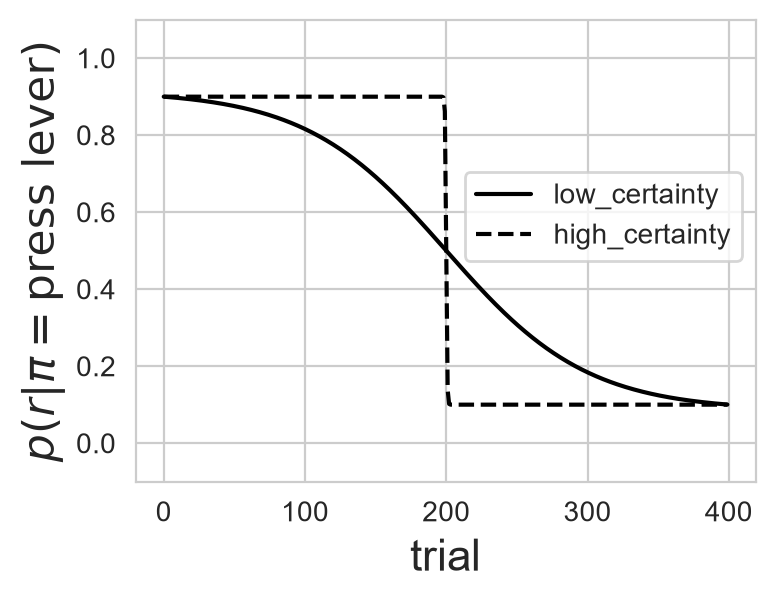

In [ ]:
"""Run Some Simulations"""
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy.special as scp
from itertools import product
import matplotlib.ticker as ticker
from matplotlib.ticker import MultipleLocator
from scipy.optimize import curve_fit
from classes import Agent, MultiArmedBandit, World
from utilities import create_long_df_gradual_change, run_simulation

np.set_printoptions(suppress=True)
sns.set_style("whitegrid")


from utilities import create_long_df_gradual_change, plot_reward_regime, run_simulation

np.random.seed(1)
dpi = 200

pars = {}
pars["TAU"] = 400
pars["hs"] = np.array([1000, 10, 1])
pars["utility"] = np.array([0.025, 0.95, 0.025])
pars["context_volatility"] = 0.99
pars["nsims"] = 200
pars["debug"] = False

pars["T"] = 2
pars["na"] = 2
pars["ns"] = pars["na"] + 1
pars["no"] = pars["ns"]
pars["nr"] = 3
pars["nc"] = 2
pars["npi"] = pars["na"]**(pars["T"]-1)
pars["train_trials"] = 0
pars["switch"] = pars["TAU"]//2
pars["training_protocol"] = [np.array([0]*(pars["switch"]+pars["train_trials"]) + [1]*pars["switch"])]
pars["changing_rewards"] = True
pars["changing_utility"] = False

pars["k_range"] = [0.02, 3.]
h_order = {h: label for h, label in zip(pars["hs"], ["no habit", "moderate habit", "strong habit"])}
env_order = {k: label for k, label in zip(pars["k_range"], ["low certainty", "high certainty"])}

start = 0.9
stop = 0.1
logistic = lambda x, k: stop - (start-stop) / (np.exp(pars["switch"]*k) - 1) \
                        + (np.exp(pars["switch"]*k) + 1) / (np.exp(pars["switch"]*k) - 1) \
                        * (start-stop)/(1+np.exp(k*(x-pars["switch"])))

reward_schedules = []
for k in pars["k_range"]:
    x = np.arange(0, pars["switch"]*2, 1)
    p_win = logistic(x, k)
    Rho = np.zeros([pars["nr"], pars["ns"], pars["TAU"]])
    Rho[:, :, pars["train_trials"]:] = np.array([
        [1-p_win, p_win, np.zeros(pars["TAU"])],
        [p_win, 1-p_win, np.zeros(pars["TAU"])],
        [np.zeros(pars["TAU"]), np.zeros(pars["TAU"]), np.ones(pars["TAU"])],
    ])
    Rho[:, :, :pars["train_trials"]] = Rho[:, :, pars["train_trials"]][:, :, None]
    reward_schedules.append((Rho, k))

plot_reward_regime(pars["k_range"], pars["switch"], pars["TAU"], start, stop, dpi=dpi)
plt.ylabel(r"$p(r|\pi=\text{press lever})$", fontsize=16)

agent_instance = np.arange(pars["nsims"])
context_volatilities = np.array([pars["context_volatility"]])
parameter_combinations = product(
    agent_instance, pars["hs"], pars["training_protocol"], context_volatilities, reward_schedules
)

sim_params = []
for pi, p in enumerate(parameter_combinations):
    par = pars.copy()
    par["rep"] = p[0]
    par["h"] = p[1]
    par["training_protocol"] = p[2]
    par["context_volatility"] = p[3]
    par["Rho"] = p[4][0]
    par["decay_rate"] = p[4][1]
    par["sim"] = pi
    sim_params.append(par)

long_dfs = []
for pi, par in enumerate(sim_params):
    print(f"just finished sim {par['sim']}") if pi % 250 == 0 else None
    world, _, _ = run_simulation(**par)
    long_dfs.append(create_long_df_gradual_change(world, par, env_order, h_order))

env_order = [item for key, item in env_order.items()] 
h_order = [item for key, item in h_order.items()]

long_df = pd.concat(long_dfs)
long_df = long_df.astype({
    "action": "category",
    "habitual_tendency": "category",
    "reward_decay_rate": "category",
    "h": pd.CategoricalDtype(categories=h_order, ordered=True),
    "environment_type": pd.CategoricalDtype(categories=env_order, ordered=True),
})
name = f"data_degradation_{pars['TAU']}_util{pars['utility'][1]}_context{pars['context_volatility']}"
long_df.to_csv(name + "_long.csv", index=False)

#### Analyse and plot curve fitting results

C:\Users\siahr\AppData\Local\Temp\ipykernel_14720\180958413.py:76: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  g.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)
C:\Users\siahr\AppData\Local\Temp\ipykernel_14720\180958413.py:76: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  g.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)


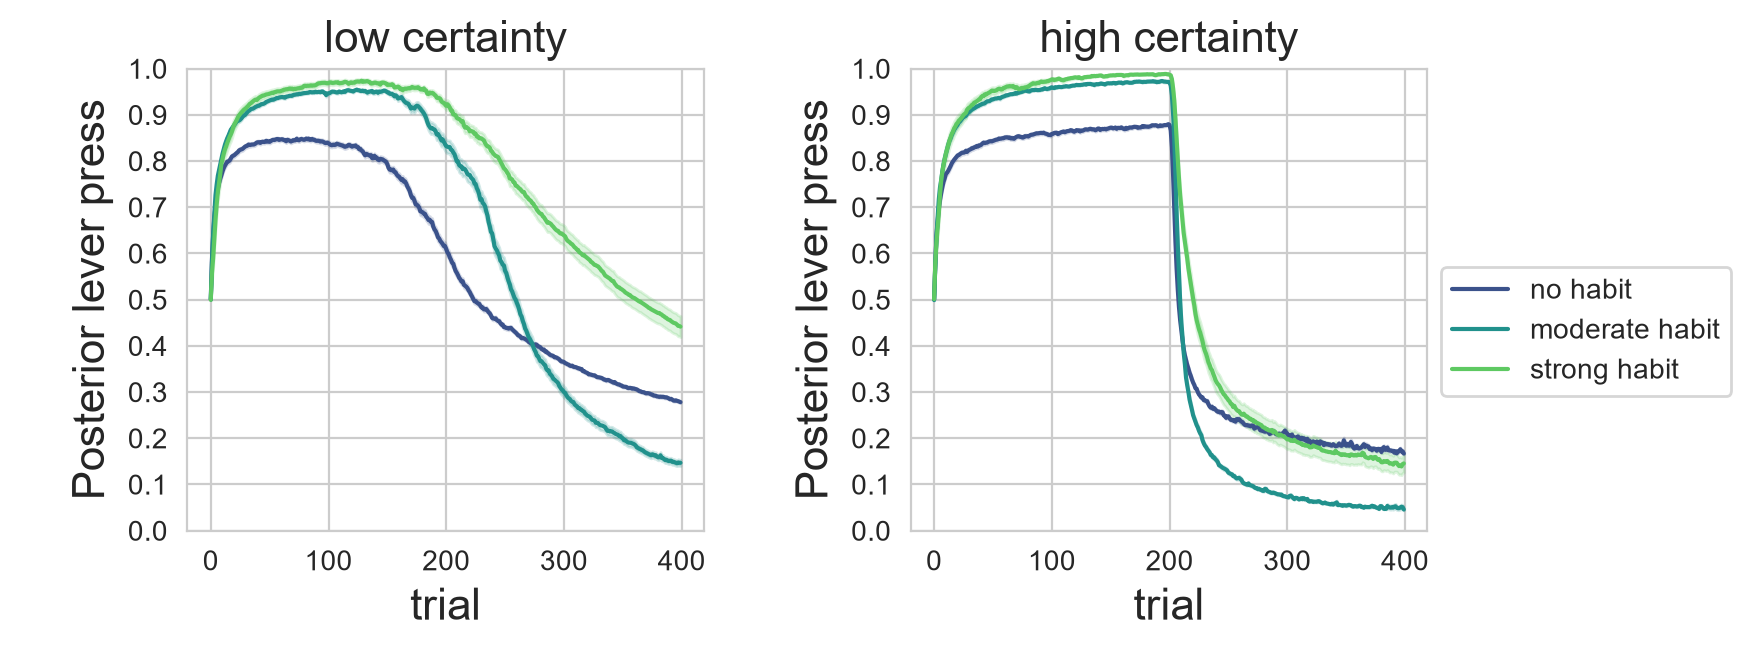

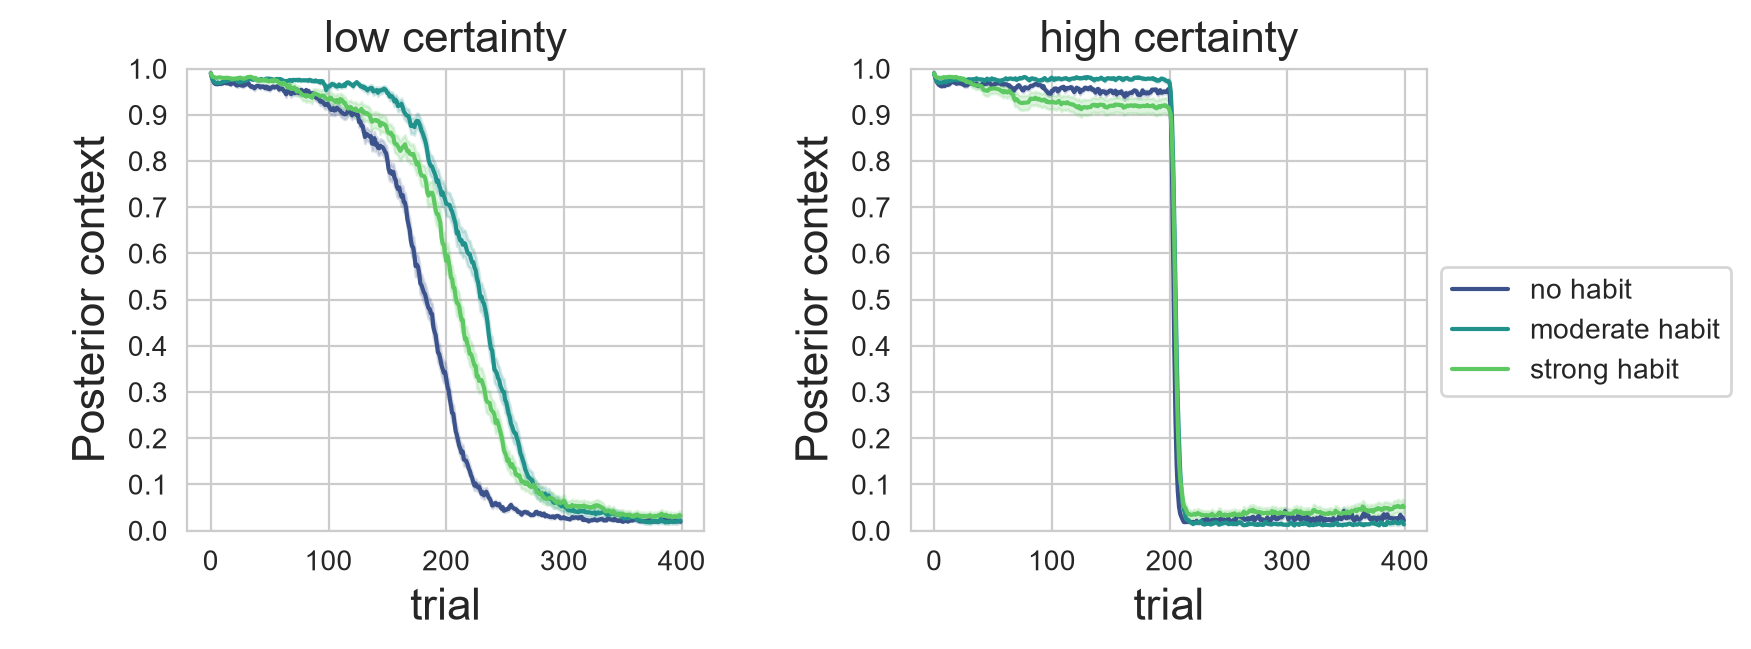

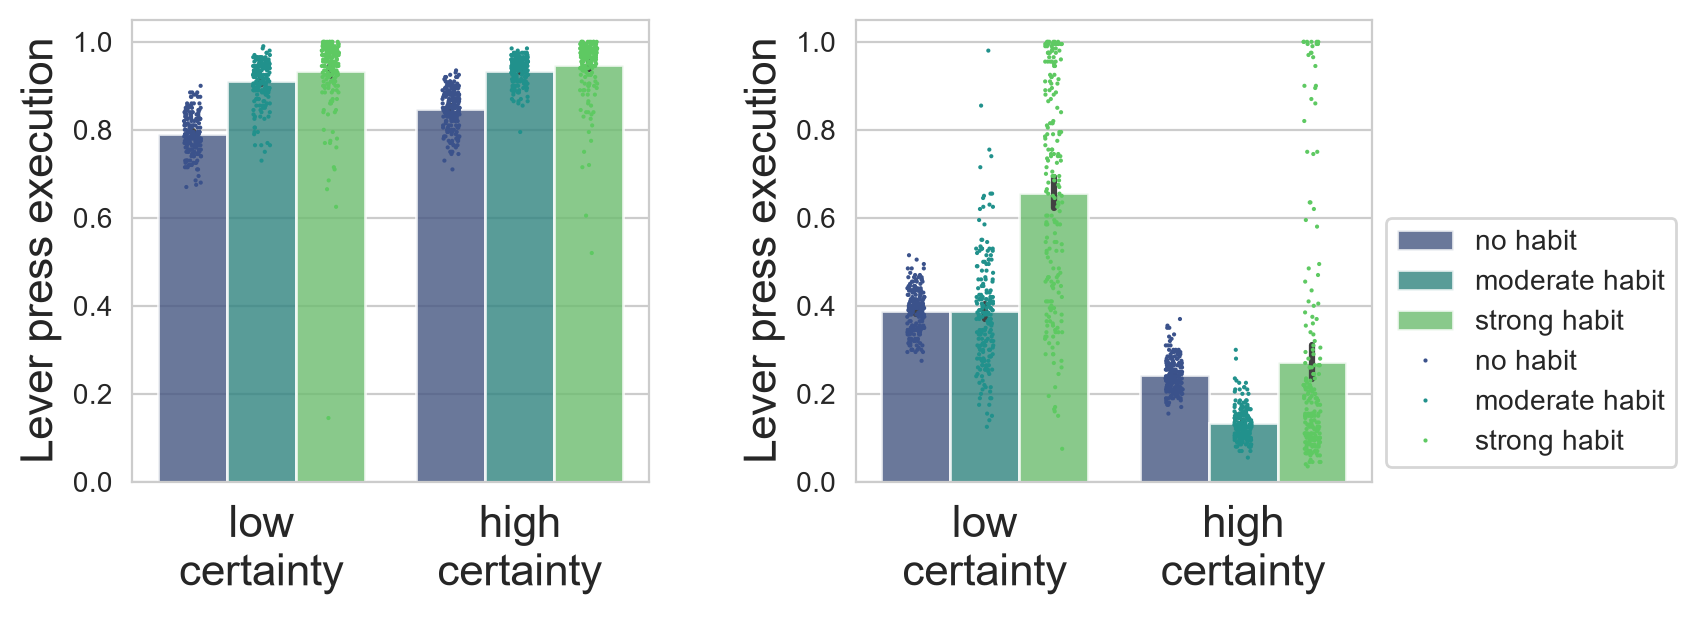

In [8]:
# df = pd.read_csv("data_degradation_400_util0.95_context0.99.csv")
df_long = pd.read_csv("data_degradation_400_util0.95_context0.99_long.csv")

K = len(env_order)

plot_df = df_long.set_index(["h","environment_type","run","tau","t"])


"""      Policy posterior        """
plt.figure(figsize=(8,3),dpi=dpi)
for ki, k in enumerate(env_order):

	plt.subplot(1,K,ki+1)
	g = sns.lineplot(data=plot_df.loc[:,k,:,:,0].reset_index(), x = "tau", y="posterior_pi0", hue="h", errorbar="se", palette="viridis", hue_order=h_order)
	g.set_ylabel("\nPosterior lever press", fontsize=16)
	g.set_xlabel("trial",fontsize=16)
	g.set_title(env_order[ki], fontsize=16)
	g.set_ylim([0,1])
	g.yaxis.set_major_locator(ticker.MultipleLocator(base=0.1)) 
	if ki == len(env_order)-1:
		g.legend(title=None, bbox_to_anchor=(1,0.6))
	else:
		g.get_legend().remove()	
plt.subplots_adjust(wspace=0.4)


"""      Context posterior       """
# shows that the slower the change the more uncertain the environment.
# what is my prediction for a slowly varying environment? Weak habit learners are driven purely by goal-directed value of an action.
# They would be less exploitative but infer a context switch faster. 
# They will behave more optimally once context changes


plt.figure(figsize=(8,3),dpi=dpi)
for ki, k in enumerate(env_order):
	# display(plot_df.loc[:,k,:,:,0].reset_index().head())
	g = plt.subplot(1,K,ki+1)
	# g.vlines(x=200,ymin=0,ymax=1, color="black",alpha=0.8)
	sns.lineplot(data=plot_df.loc[:,k,:,:,0].reset_index(), x = "tau", y="posterior_context_c0", hue="h", errorbar="se", palette="viridis", hue_order=h_order)
	g.set_ylabel("\nPosterior context",fontsize=16)
	g.yaxis.set_major_locator(ticker.MultipleLocator(base=0.1)) 
	g.set_xlabel("trial",fontsize=16)
	g.set_title(env_order[ki], fontsize=16)
	g.set_ylim([0,1])
	if ki == len(env_order)-1:
		g.legend(title=None, bbox_to_anchor=(1,0.6))
	else:
		g.get_legend().remove()	
plt.subplots_adjust(wspace=0.4)

"""reward gathered pre and post optimal action changing"""
# plot_df = df_long.query("t==1").groupby(by=["h","environment_type","run","true_context"])["reward"].sum()
# plot_df = plot_df.reset_index().query("true_context == 0")
# plt.figure()
# sns.barplot(data=plot_df, x="environment_type", y="reward", hue="h", hue_order=h_order, order=env_order, palette="viridis")

# plt.figure()
# sns.barplot(data=plot_df, hue="environment_type", y="reward", x="h", hue_order=env_order, order=h_order, palette="tab10")
# # plot_df.head()

"""Executed action"""

plot_df = df_long.query("t==0").groupby(by=["h","environment_type","run","true_context"])["action"].value_counts(normalize=True, dropna=False)
plot_df = plot_df.reset_index().query("action==0")

plt.figure(figsize=(8,3),dpi=dpi)
for ci, c in enumerate(plot_df.true_context.unique()):
	# display(plot_df.loc[:,k,:,:,0].reset_index().head())
	plt.subplot(1,plot_df.true_context.unique().size,ci+1) 
	g = sns.barplot(data=plot_df.query(f"true_context =={ci}"), x="environment_type", order=env_order, y="proportion", hue="h", hue_order=h_order, palette="viridis", alpha=0.8)
	g = sns.stripplot(data=plot_df.query(f"true_context =={ci}"), x="environment_type", order=env_order, y="proportion", hue="h", hue_order=h_order, palette="viridis", dodge=True, s=1.5)
	g.set_xlabel(None)
	g.set_ylabel("Lever press execution", fontsize=16)
	g.legend(title=None)
	g.set_ylim([0,1.05])
	g.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)

	if ci == len(env_order)-1:
		g.legend(title=None, bbox_to_anchor=(1,0.6))
	else:
		g.get_legend().remove()	
plt.subplots_adjust(wspace=0.4)





' Run refitting '

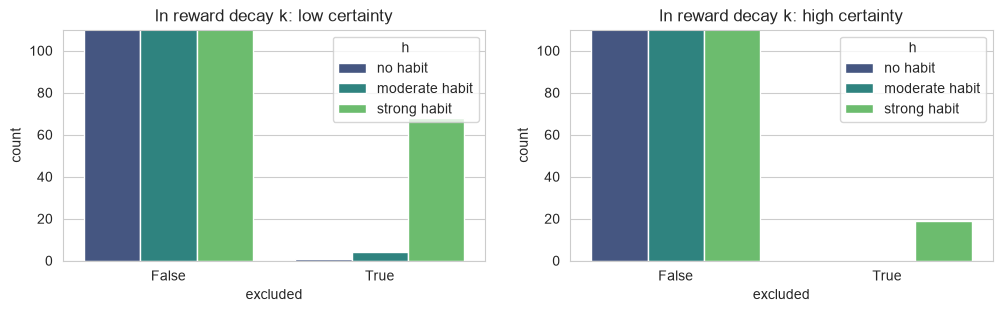

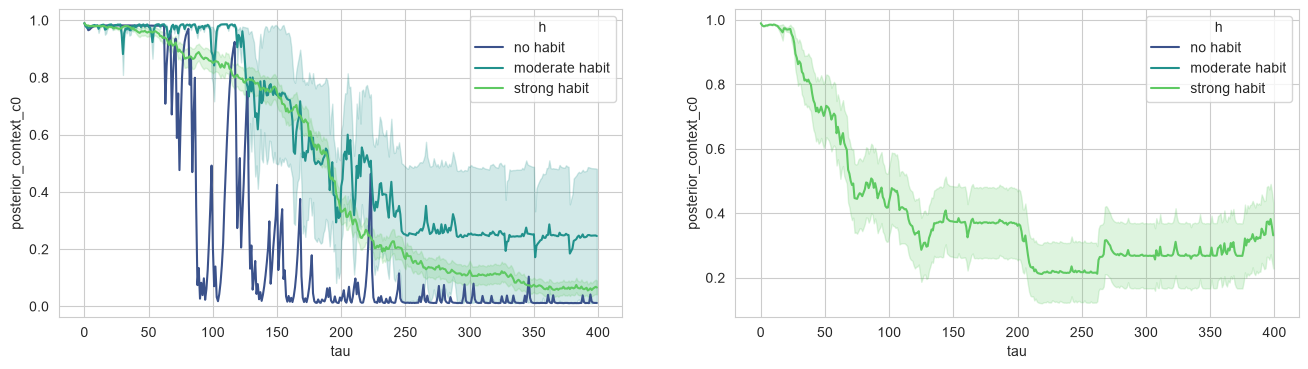

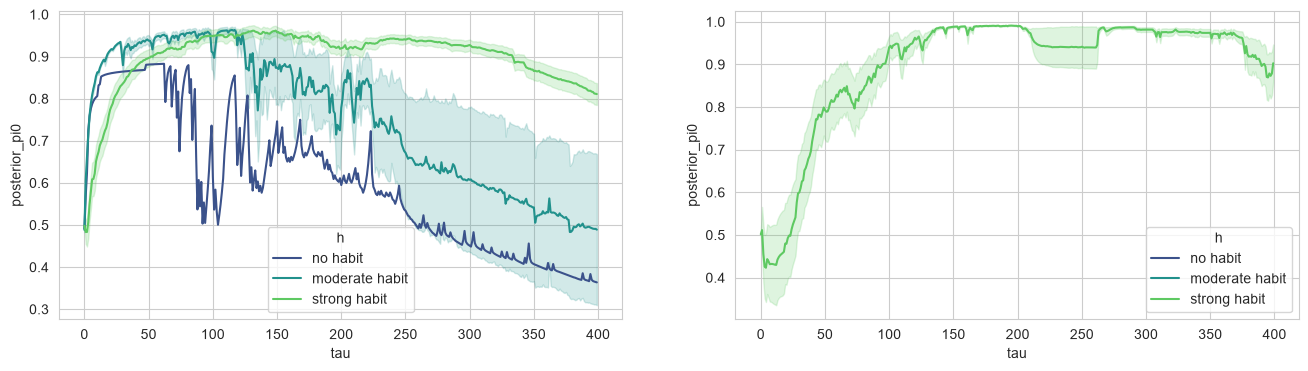

In [11]:
df_long = pd.read_csv("data_degradation_400_util0.95_context0.99_long.csv")

TAU = pars["TAU"]
context_volatility = df_long.context_volatility.unique()
# print(f"utility:\n{[float(util) for util in (df_long.iloc[0][["utility_0","utility_1", "utility_2"]].to_list())]}")
util_list = [float(util) for util in df_long.iloc[0][["utility_0", "utility_1", "utility_2"]].to_list()]

# df_long["h"] = np.log10(df_long["h"]).round(2) # df_long["h"]#
# df_long["reward_decay_rate"] = np.log(df_long["reward_decay_rate"]).round(2) # df_long["reward_decay_rate"]#
# df_long["h"] = df_long["h"].astype("category")

### clean fitting data
df_long["excluded"] = False
df_long["exclusion_reason"] = None
df_long.loc[df_long["policy_a"] < 0.35, ["excluded", "exclusion_reason", "policy_c"]] = [True, "policy", (TAU//2)+1]   # exclude agents that don't infer second policy with probability higher than 0.35

df_long.loc[df_long["context_a"] < 0.35, ["excluded","exclusion_reason", "context_c"]] = [True, "context", (TAU//2)+1]  # exclude agents that don't infer second context with probability higher than 0,35

df_long.loc[df_long["context_c"].isna(),  ["excluded","exclusion_reason", "context_c"]] = [True, "context", (TAU//2)+1] # exclude all agents where no sigmoid could be fitted at all

df_long.loc[df_long["policy_c"].isna(),  ["excluded", "exclusion_reason", "policy_c"]] = [True, "policy", (TAU//2)+1] # exclude all agents where no sigmoid could be fitted at all

df_long.loc[df_long["context_c"] > TAU//2, ["excluded","exclusion_reason", "context_c"]] = [True, "context", (TAU//2)+1] # 
						   #
df_long.loc[(df_long["policy_c"] > 130) & (df_long["policy_a"] > 0.7) & (df_long["policy_a"] > 1.01), ["excluded", "exclusion_reason", "policy_c"]] = [True, "policy", (TAU//2)+1]

df_long.loc[df_long["context_c"] < -TAU//4, ["excluded","exclusion_reason", "context_c"]] = [True, "context", (TAU//2)+1]

df_long.loc[df_long["policy_c"] < -TAU//4, ["excluded", "exclusion_reason", "policy_c"]] = [True, "policy", (TAU//2)+1]

""" Before setting TAU separately"""
# df_long.loc[df_long["excluded"] == True, ["context_c", "policy_c"]] = (TAU//2) + 1

# df_long.loc[df_long["policy_a"] < 0.35, "excluded"] = True   # exclude agents that don't infer second policy with probability higher than 0.35

# df_long.loc[df_long["context_a"] < 0.35, "excluded"] = True  # exclude agents that don't infer second context with probability higher than 0,35

# df_long.loc[df_long["context_c"].isna(),  "excluded"] = True # exclude all agents where no sigmoid could be fitted at all

# df_long.loc[df_long["policy_c"].isna(),  "excluded"] = True # exclude all agents where no sigmoid could be fitted at all

# df_long.loc[df_long["context_c"] > TAU//2, "excluded"] = True # 
# 						   #
# df_long.loc[(df_long["policy_c"] > 130) & (df_long["policy_a"] > 0.7) & (df_long["policy_a"] > 1.01), "excluded"] = True

# df_long.loc[df_long["context_c"] < -TAU//4, "excluded"] = True

# df_long.loc[df_long["policy_c"] < -TAU//4, "excluded"] = True

# df_long.loc[df_long["excluded"] == True, ["context_c", "policy_c"]] = (TAU//2) + 1


""" Show amounts of excluded agents per simulation subgroup  """
df = df_long.query("t == 0 and tau == 0")
K = len(env_order)
fig, axes = plt.subplots(1,K, figsize=(12,3))

for ki, k in enumerate(env_order):
	sns.countplot(ax=axes[ki], data=df.query(f"environment_type == '{k}'"),x="excluded", hue="h", palette="viridis",hue_order=h_order)

	axes[ki].set_title(f"ln reward decay k: {k}")
	axes[ki].set_ylim([0,110])

"""  Inferred posterior over contexts for excluded agents """

plot_df = df_long.set_index(["excluded","h","environment_type","run","tau","t"])

plt.figure(figsize=(16,4))
for ki, k in enumerate(env_order):
	# display(plot_df.loc[:,k,:,:,0].reset_index().head())
	plt.subplot(1,K,ki+1)
	sns.lineplot(data=plot_df.loc[True,:,k,:,:,0].reset_index(), x = "tau", y="posterior_context_c0", hue="h", errorbar="se", palette="viridis",hue_order=h_order)

"""  Inferred posterior over policies for excluded agents """

plt.figure(figsize=(16,4))
for ki, k in enumerate(env_order):
	# display(plot_df.loc[:,k,:,:,0].reset_index().head())
	plt.subplot(1,K,ki+1)
	sns.lineplot(data=plot_df.loc[True,:,k,:,:,0].reset_index(), x = "tau", y="posterior_pi0", hue="h", errorbar="se", palette="viridis",hue_order=h_order)

""" Run refitting """

# df = df_long[df_long["excluded"]]

# grouped = df.groupby(["environment_type", "h", "exclusion_reason"], observed=True)
# for (k,h, exclusion_reason), group in grouped:
	
# 	# create mask to identify rows to change in df_long
# 	sims = group.sim.unique()
# 	print("exclusion reason: ", exclusion_reason)
# 	mask = df_long["sim"].isin(sims)

# 	# run fitting on the mean posterior of all excluded agents
# 	gr = group.set_index(["tau","t"])

# 	q_action = gr.loc[(slice(None),0), "posterior_pi0"]
# 	q_action = q_action.groupby(by="tau").mean().to_numpy()

# 	q_context = gr.loc[(slice(None),1), "posterior_context_c0"]
# 	q_context = q_context.groupby(by="tau").mean().to_numpy()
	
# 	context_params, context_pcov, context_func, policy_params, policy_func, se = fit_posterior_traces(q_context, q_action, switch, TAU)

# 	# change values in df_long
# 	if exclusion_reason == "policy":		
# 		cols = ["policy_a", "policy_b", "policy_c", "policy_d", "policy_func"]
# 		vals = np.array(list(policy_params) + [policy_func])
# 		vals[np.isnan(vals)] = TAU // 2
# 		for col, val in zip(cols,vals):
# 			df_long.loc[mask, col] = val
# 		print(f"h:{h}, env:{k}, exclusion: {exclusion_reason}, policy_c:{vals[2]}")
	
# 	if exclusion_reason == "context":
# 		cols = ["context_a", "context_b", "context_c", "context_d", "context_func"]
# 		vals = np.array(list(context_params) + [context_func])
# 		vals[np.isnan(vals)] = TAU // 2
# 		for col, val in zip(cols,vals):
# 			df_long.loc[mask, col] = val
# 		print(f"h:{h}, env:{k}, exclusion: {exclusion_reason}, context_c:{vals[2]}")


#	# change values in df_long
#	# cols = ["context_a", "context_b", "context_c", "context_d", "context_func", "policy_a", "policy_b", "policy_c", "policy_d", "policy_func"]
#	# vals = np.array(list(context_params) + [context_func] + list(policy_params) + [policy_func])
#	# vals[np.isnan(vals)] = TAU // 2
#	# for col, val in zip(cols,vals):
#	# 	df_long.loc[mask, col] = val

#	# print(f"h:{h}, env:{k}, context_c:{vals[2]}, policy_c:{vals[7]}")


C:\Users\siahr\AppData\Local\Temp\ipykernel_14720\3790656516.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)
C:\Users\siahr\AppData\Local\Temp\ipykernel_14720\3790656516.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)


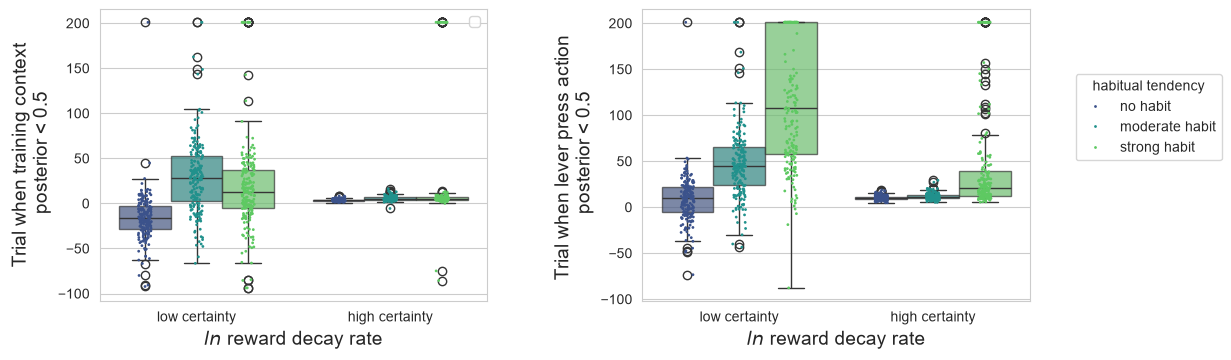

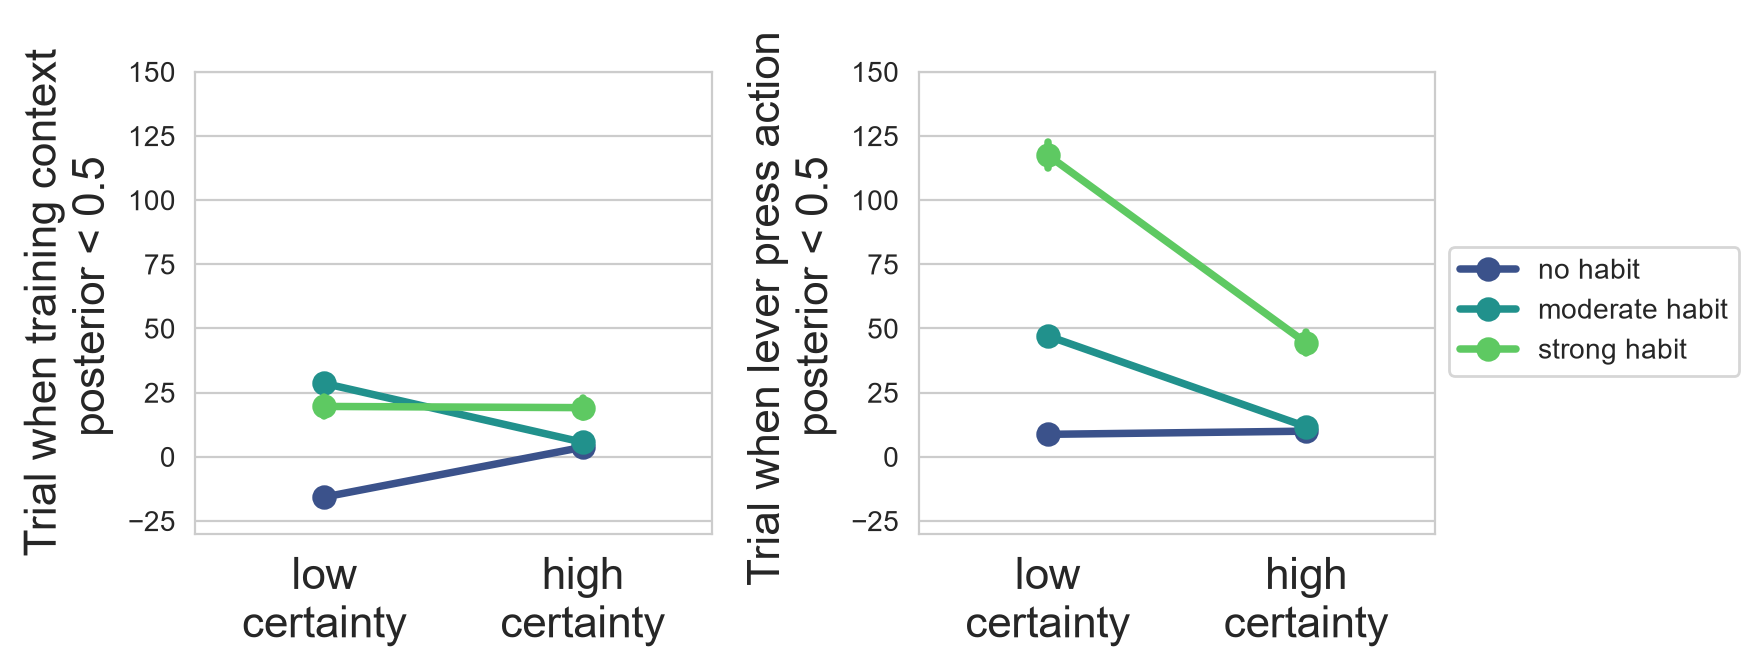

In [12]:
df = df_long.query("t == 0 and tau == 0")

""" Trial at which novel context inferred BOXPLOT"""

fig, axes = plt.subplots(1,2, figsize=(10,3.5))
plt.tight_layout()
plt.subplots_adjust(wspace=0.4)
sns.boxplot(ax=axes[0], data=df, x="environment_type", y="context_c", hue="h", boxprops=dict(alpha=.7), palette="viridis",legend=None,hue_order=h_order, order=env_order)
sns.stripplot(ax=axes[0], data=df, x="environment_type", y="context_c", hue="h", palette="viridis", dodge=True, s=2,hue_order=h_order, order=env_order)
sns.boxplot(ax=axes[1], data=df, x="environment_type", y="policy_c", hue="h", boxprops=dict(alpha=.7), palette="viridis",legend=None,hue_order=h_order, order=env_order)
sns.stripplot(ax=axes[1], data=df, x="environment_type", y="policy_c", hue="h", palette="viridis", dodge=True, s=2,hue_order=h_order, order=env_order)

axes[0].set_ylabel("Trial when training context\n posterior < 0.5", fontsize=14)
axes[1].set_ylabel("Trial when lever press action \n posterior < 0.5", fontsize=14)

axes[0].legend([])
axes[1].legend(bbox_to_anchor=(1.,0.8), title="habitual tendency")


for ax in axes:
	# ax.set_ylim([-30,150])
	ax.set_xlabel(rf"$ln$ reward decay rate", fontsize=14)
axes[1].legend(bbox_to_anchor=(1.1,0.8), title=r"habitual tendency")


""" Trial at which novel context inferred POINTPLOT"""

fig, axes = plt.subplots(1,2, figsize=(8,3),dpi=dpi)
# plt.tight_layout()
plt.subplots_adjust(wspace=0.4)
sns.pointplot(ax=axes[0], data=df, x="environment_type", y="context_c", hue="h", marker="o",errorbar="se",palette="viridis",legend=None,hue_order=h_order, order=env_order)
sns.pointplot(ax=axes[1], data=df, x="environment_type", y="policy_c", hue="h", marker="o", errorbar="se",palette="viridis",hue_order=h_order, order=env_order)
axes[0].set_ylabel("Trial when training context\n posterior < 0.5", fontsize=16)
axes[1].set_ylabel("Trial when lever press action \n posterior < 0.5", fontsize=16)

for ax in axes:
	ax.set_ylim([-30,150])
	ax.set_xlabel(None)
	ax.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)
axes[1].legend(bbox_to_anchor=(1,0.65), title=None)




In the first two plots we look at the distribution of the inferred inflection point parameters for the posterior over contexts and policies (context_c and policy_c). e inflection point parameter corresponds to the trial at which fitted sigmoid becomes more than 50% of its max values. As explained above, cases where sigmoid could not be fitted or fitted nonsense, the inflection point was set to TAU//2. 

Plots:
1. Violin plot of inferred inflection points for the context and policy posteriors. 
2. Same data, but showing the average inflection point for different habit learneres and different rates of reward decay, similar to the plot in Sarah's paper.
3. Plot of how many inflection points were manually set to TAU//2, corresponding to the number of agents, that failed to acquiere correct contextual structure alltogether.

From these plots can see that overall the quicker rewards decay, the faster agents perceive a change in context, as expected. Additionally, more agents manage to learn correct contextual structure and switch action in response to context change. 

Gradual changes in reward instead lead to more within context adaptation and slower shift to learning a novel context (higher policy_c, context_c and more excluded (failed) agents).

Importantly, **this effect is the most pronounced for strong habit learners (those with log habitual_tendency close to 0)** as hypothesized, with strong habit learners having the most failed agents and the highest inflection points. 

Overall **very few habit learners completely fail to infer presence of a new context**. The reward prediction error drives them to eventually notice that something new has happened. Even so, in practice they either 

1. fail to learn an adequate second context (with reward distributions for that context staying close to uniform).
2. infer the presence of a second context, with the correct contingencies (higher reward rate for action 2 than action 1) but are unable to switch response nonetheless, due to habit bleedthrough. From an SUD perspective, the agent is capable of recognizing that it is in a novel situation where the originally learned drug action is no longer rewarding but the compulsion to consume persists even in this new context.

Below are some examples of such behaviour.

